# Monthly EM Update

This notebook is the single runbook for the market-data tables and charts used in the EM Updates slide workflow. PowerPoint assembly remains manual.

Run all cells from top to bottom. To prepare a different monthly update, change only `year` and `month` in the configuration cell. The notebook derives the reporting month, previous month, previous year, query windows, comparison labels, chart titles, and output filename from those values.

The main chart focus is NSW1 two-hour/four-hour battery assets and QLD1 two-hour battery assets. Price, generation, demand, and gas-weighted price outputs are produced for both target regions. Data is never automatically imputed; review the quality reports before using charts in slides.


## Configuration and API preflight

In [16]:
import calendar
import datetime as dt
import importlib
import os
import numpy as np

# API configuration. The endpoint is intentionally kept compatible with the original workflow.
os.environ['NEMPOINT_URL'] = 'https://www.neopoint.com.au/data/query'

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import pandas as pd

import helper_functions
importlib.reload(helper_functions)

from helper_functions import (
    aggregate_generation_to_half_hour,
    aggregate_to_half_hour,
    average_availability_profile,
    average_demand_by_half_hour,
    broken_axis_limits,
    build_generation_profile,
    build_time_series_quality_report,
    calculate_gas_weighted_price,
    daily_average_availability,
    get_fueltype_availability,
    get_fueltype_generation,
    get_operational_demand,
    get_price_data,
    GetSpreads,
    half_hour_time_labels,
    pivot_format_data,
    summarise_availability,
)

if not os.getenv('NEMPOINT_API_KEY'):
    raise RuntimeError('Set NEMPOINT_API_KEY before running this notebook.')

# Brand styling (Akaysha Energy Brand Guidelines, Nov 2024).
# Baikal is the brand typeface but isn't available outside licensed design tools;
# Inter is the brand's documented fallback for external software such as this notebook.
fm.fontManager.addfont('fonts/Inter.ttf')
plt.rcParams['font.family'] = 'Inter'

AKAYSHA_PINE = '#003723'
AKAYSHA_MOSS = '#00743C'
AKAYSHA_JADE = '#007864'   # 'Jade' in the brand spectrum
AKAYSHA_SPRING = '#46C86E'  # 'Spring' in the brand spectrum
AKAYSHA_LIME = '#C7F77A'
AKAYSHA_AMARANTH = '#E75751'
AKAYSHA_AMBER = '#F69B4E'
AKAYSHA_AQUA = '#99D9E7'
AKAYSHA_AZURE = '#509EE3'

# Monthly run configuration. Change year/month here only.
year = 2026
month = 10
target_regions = ['NSW1', 'QLD1']
target_durations = {'NSW1': [2, 4], 'QLD1': [2]}
regions = ['NSW1', 'QLD1', 'SA1', 'TAS1', 'VIC1']
durations = sorted({duration for values in target_durations.values() for duration in values})

if not 1 <= month <= 12:
    raise ValueError('month must be between 1 and 12')
if not set(target_regions).issubset(regions):
    raise ValueError(f'target_regions must be selected from {regions}')
if set(target_regions) != set(target_durations):
    raise ValueError('target_durations must define every target region')

month_name = calendar.month_name[month]
output_path = f'{month_name} {year} Spreads.csv'

month_start = dt.datetime(year, month, 1)
month_end = dt.datetime(year + (month == 12), (month % 12) + 1, 1)
previous_month_start = (month_start - dt.timedelta(days=1)).replace(day=1)
previous_month_end = month_start
previous_year_start = dt.datetime(year - 1, month, 1)
previous_year_end = dt.datetime(year - 1 + (month == 12), (month % 12) + 1, 1)

# All price charts need the reporting month and its previous month.
price_start = previous_month_start
price_end = month_end


## Price data and spreads

This section retrieves prices for the previous and reporting months, reports data quality, calculates daily spreads for all configured regions and durations, exports the daily spread table, and creates spread and price comparison charts.

In [17]:
# Retrieve the reporting month and previous month for price profiles and spreads.
price_data = get_price_data(price_start, price_end)
price_quality_report = build_time_series_quality_report(
    price_data,
    group_columns=['REGIONID'],
)
price_quality_report
price_data.to_csv('price_data.csv')

c:\anaconda3\Lib\site-packages\urllib3\connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'www.neopoint.com.au'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


In [18]:
price_table = pivot_format_data(price_data)
spreads, daily_spreads, spread_diagnostics = GetSpreads(
    price_table[regions],
    durations=durations,
    StartPeriods=[price_start.date()],
    EndPeriods=[price_end.date()],
    incomplete_day_policy='exclude',
    return_diagnostics=True,
)
spread_diagnostics


{'expected_intervals_per_day': 288,
 'available_day_count': 62,
 'valid_day_count': 61,
 'excluded_days': [{'date': '2026-08-31',
   'reason': 'expected 288 intervals, found 1'}]}

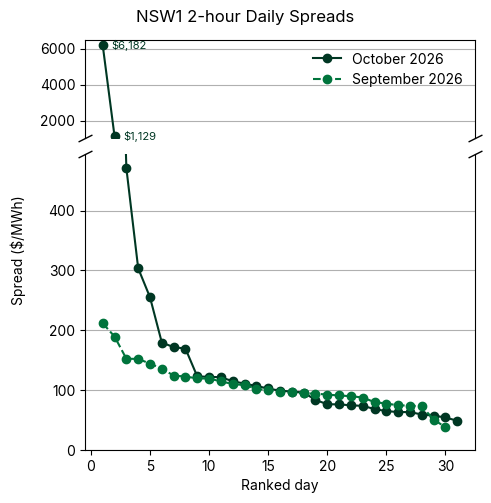

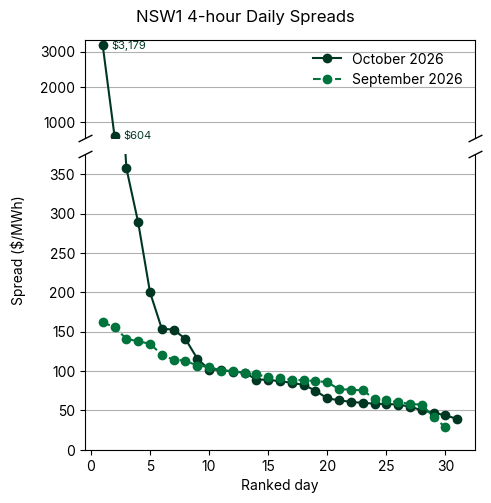

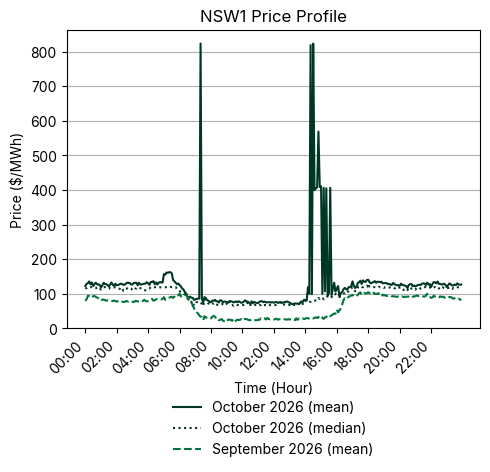

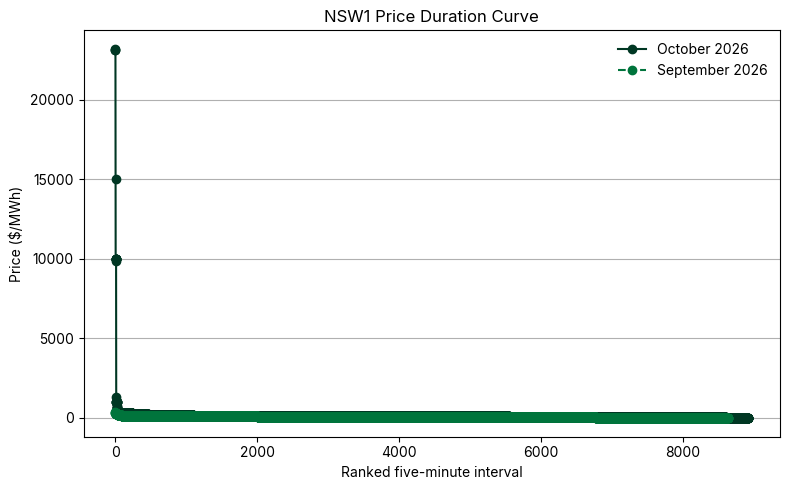

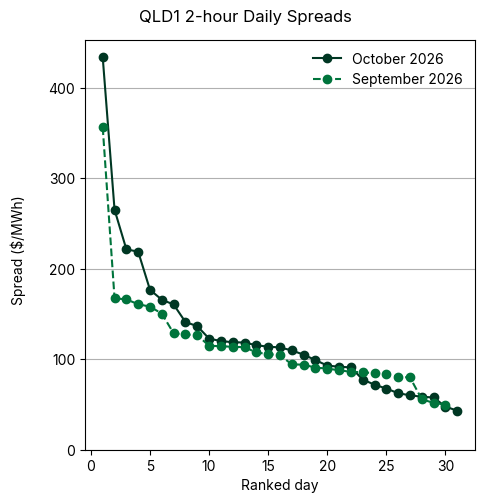

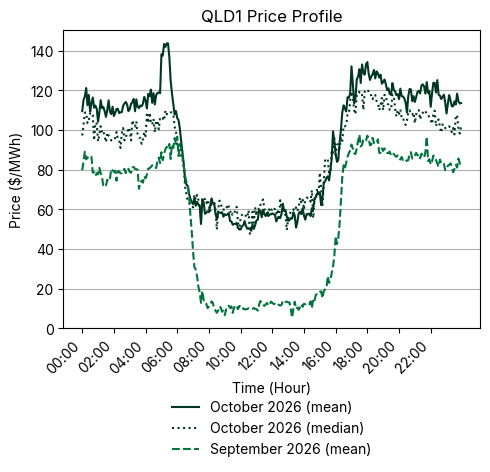

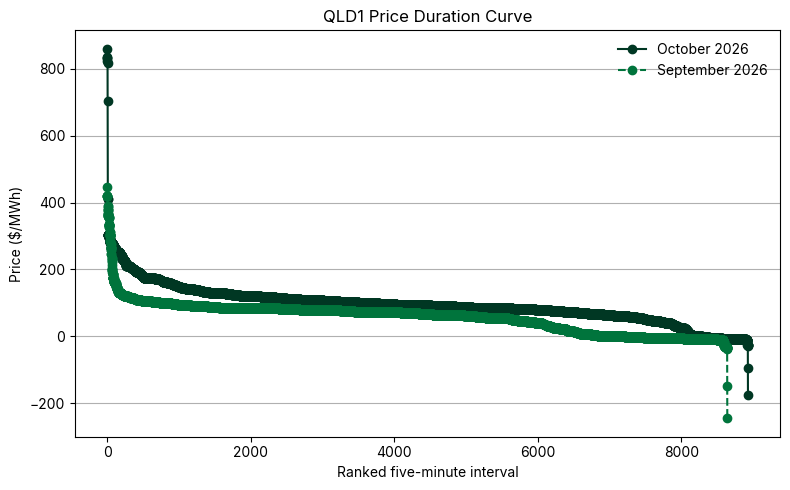

In [ ]:
daily_spreads = daily_spreads.copy()
daily_spreads.index = pd.to_datetime(daily_spreads.index)
daily_spreads['Month'] = daily_spreads.index.month
daily_spreads.to_csv(output_path)

previous_month_number = previous_month_start.month
previous_month_name = calendar.month_name[previous_month_number]

for region in target_regions:
    for duration in target_durations[region]:
        duration_column = f'{region}.{duration}'
        current_spreads = daily_spreads[
            daily_spreads['Month'] == month
        ][duration_column].sort_values(ascending=False).reset_index(drop=True)
        previous_spreads = daily_spreads[
            daily_spreads['Month'] == previous_month_number
        ][duration_column].sort_values(ascending=False).reset_index(drop=True)

        spread_series = [
            (current_spreads, dict(color=AKAYSHA_PINE, label=f'{month_name} {year}')),
            (previous_spreads, dict(color=AKAYSHA_MOSS, linestyle='--', label=f'{previous_month_name} {year}')),
        ]
        axis_limits = broken_axis_limits(pd.concat([current_spreads, previous_spreads]))

        if axis_limits is None:
            fig, ax = plt.subplots(figsize=(5, 5))
            for values, style in spread_series:
                ax.plot(range(1, len(values) + 1), values, marker='o', **style)
            ax.set_ylim(bottom=0)
            ax.grid(axis='y')
            ax.legend(frameon=False)
        else:
            # Broken y-axis: upper panel isolates event-driven days, lower panel keeps the typical range readable.
            (low_min, low_max), (high_min, high_max) = axis_limits
            fig, (ax_high, ax) = plt.subplots(
                2, 1, sharex=True, figsize=(5, 5),
                gridspec_kw={'height_ratios': [1, 3], 'hspace': 0.08},
            )
            for values, style in spread_series:
                for panel in (ax_high, ax):
                    panel.plot(range(1, len(values) + 1), values, marker='o', **style)
            ax.set_ylim(low_min, low_max)
            ax_high.set_ylim(high_min, high_max)
            for panel in (ax_high, ax):
                panel.grid(axis='y')
            ax_high.spines['bottom'].set_visible(False)
            ax.spines['top'].set_visible(False)
            ax_high.tick_params(axis='x', which='both', bottom=False)
            ax_high.legend(frameon=False)

            # Label points that only appear in the upper panel.
            for values, style in spread_series:
                for rank, value in zip(range(1, len(values) + 1), values):
                    if value >= high_min:
                        ax_high.annotate(
                            f'${value:,.0f}', (rank, value),
                            textcoords='offset points', xytext=(6, 0),
                            va='center', fontsize=8, color=style['color'],
                        )

            # Diagonal break marks.
            mark = dict(marker=[(-1, -0.5), (1, 0.5)], markersize=10, linestyle='none',
                        color='k', mec='k', mew=1, clip_on=False)
            ax_high.plot([0, 1], [0, 0], transform=ax_high.transAxes, **mark)
            ax.plot([0, 1], [1, 1], transform=ax.transAxes, **mark)

        ax.set_xlabel('Ranked day')
        fig.supylabel('Spread ($/MWh)', x=0.03, fontsize=plt.rcParams['axes.labelsize'])
        fig.suptitle(f'{region} {duration}-hour Daily Spreads', fontsize=plt.rcParams['axes.titlesize'])
        fig.subplots_adjust(left=0.18, right=0.96, top=0.92, bottom=0.1)
        plt.show()

    current_month_prices = price_table[price_table['Month'] == month].groupby('Interval')[region]
    current_price_profile = current_month_prices.mean()
    current_price_median = current_month_prices.median()
    previous_price_profile = (
        price_table[price_table['Month'] == previous_month_number]
        .groupby('Interval')[region]
        .mean()
    )
    plt.figure(figsize=(5, 5))
    plt.plot(
        current_price_profile.index,
        current_price_profile,
        color=AKAYSHA_PINE,
        label=f'{month_name} {year} (mean)',
    )
    plt.plot(
        current_price_median.index,
        current_price_median,
        color=AKAYSHA_PINE,
        linestyle=':',
        label=f'{month_name} {year} (median)',
    )
    plt.plot(
        previous_price_profile.index,
        previous_price_profile,
        color=AKAYSHA_MOSS,
        label=f'{previous_month_name} {year} (mean)',
        linestyle='--',
    )
    plt.xlabel('Time (Hour)')
    plt.ylabel('Price ($/MWh)')
    plt.title(f'{region} Price Profile')
    plt.xticks(
        range(0, 288, 24),
        [f'{hour:02d}:00' for hour in range(0, 24, 2)],
        rotation=45,
        ha='right',
    )
    plt.grid(axis='y')
    plt.ylim(bottom=0)
    plt.legend(
        frameon=False)
    plt.tight_layout()
    plt.show()

    current_price_duration = price_table[
        price_table['Month'] == month
    ][region].sort_values(ascending=False).reset_index(drop=True)
    previous_price_duration = price_table[
        price_table['Month'] == previous_month_number
    ][region].sort_values(ascending=False).reset_index(drop=True)
    plt.figure(figsize=(8, 5))
    plt.plot(
        range(1, len(current_price_duration) + 1),
        current_price_duration,
        marker='o',
        color=AKAYSHA_PINE,
        label=f'{month_name} {year}',
    )
    plt.plot(
        range(1, len(previous_price_duration) + 1),
        previous_price_duration,
        marker='o',
        color=AKAYSHA_MOSS,
        linestyle='--',
        label=f'{previous_month_name} {year}',
    )
    plt.xlabel('Ranked five-minute interval')
    plt.ylabel('Price ($/MWh)')
    plt.title(f'{region} Price Duration Curve')
    plt.grid(axis='y')
    plt.legend(frameon=False)
    plt.tight_layout()
    plt.show()


In [20]:
# Headline spread statistics: report mean and median together so a few event-driven days
# don't make the average look like a typical day. Paste the printed bullets into the slide.
event_day_count = 2  # number of highest-spread days treated as "event days"

spread_summary_rows = []
for region in target_regions:
    for duration in target_durations[region]:
        duration_column = f'{region}.{duration}'
        for label, month_number in [('current', month), ('previous', previous_month_number)]:
            values = (
                daily_spreads[daily_spreads['Month'] == month_number][duration_column]
                .dropna()
                .sort_values(ascending=False)
            )
            spread_summary_rows.append({
                'Region': region,
                'Duration (h)': duration,
                'Period': label,
                'Days': len(values),
                'Mean': values.mean(),
                'Median': values.median(),
                f'Mean excl. top {event_day_count}': values.iloc[event_day_count:].mean(),
                f'Top {event_day_count} share of total (%)': 100 * values.iloc[:event_day_count].sum() / values.sum(),
            })

spread_summary = pd.DataFrame(spread_summary_rows).set_index(['Region', 'Duration (h)', 'Period'])
display(spread_summary.round(1))

for region in target_regions:
    for duration in target_durations[region]:
        now = spread_summary.loc[(region, duration, 'current')]
        prev = spread_summary.loc[(region, duration, 'previous')]
        share = now[f'Top {event_day_count} share of total (%)']
        print(
            f"{region} {duration}-hour spreads averaged ${now['Mean']:,.0f}/MWh in {month_name} "
            f"(median ${now['Median']:,.0f}/MWh; ${now[f'Mean excl. top {event_day_count}']:,.0f}/MWh excluding the "
            f"{event_day_count} highest days) vs ${prev['Mean']:,.0f}/MWh in {previous_month_name} "
            f"(median ${prev['Median']:,.0f}/MWh). The {event_day_count} highest days contributed {share:.0f}% of the month's total spread."
        )

Days   Mean  Median  Mean excl. top 2  \
Region Duration (h) Period                                            
NSW1   2            current     31  348.8    98.6             120.7   
                    previous    30  107.0    97.9             100.3   
       4            current     31  218.0    86.9             102.5   
                    previous    30   94.0    91.6              89.4   
QLD1   2            current     31  125.2   113.1             109.7   
                    previous    30  114.4   105.2             103.9   

                              Top 2 share of total (%)  
Region Duration (h) Period                              
NSW1   2            current                       67.6  
                    previous                      12.5  
       4            current                       56.0  
                    previous                      11.3  
QLD1   2            current                       18.0  
                    previous                      15.3

NSW1 2-hour spreads averaged $349/MWh in October (median $99/MWh; $121/MWh excluding the 2 highest days) vs $107/MWh in September (median $98/MWh). The 2 highest days contributed 68% of the month's total spread.
NSW1 4-hour spreads averaged $218/MWh in October (median $87/MWh; $103/MWh excluding the 2 highest days) vs $94/MWh in September (median $92/MWh). The 2 highest days contributed 56% of the month's total spread.
QLD1 2-hour spreads averaged $125/MWh in October (median $113/MWh; $110/MWh excluding the 2 highest days) vs $114/MWh in September (median $105/MWh). The 2 highest days contributed 18% of the month's total spread.


In [21]:
# Monthly price statistics per region (five-minute prices, $/MWh).
low_price_threshold = 0
high_price_threshold = 300

price_stats_source = price_table[regions].copy()
price_stats_source['Year'] = price_stats_source.index.year
price_stats_source['Month'] = price_stats_source.index.month

price_stats_rows = []
for (stats_year, stats_month), group in price_stats_source.groupby(['Year', 'Month']):
    for region in regions:
        prices = group[region].dropna()
        interval_count = len(prices)
        low_count = int((prices <= low_price_threshold).sum())
        high_count = int((prices >= high_price_threshold).sum())
        price_stats_rows.append({
            'Year': stats_year,
            'Month': stats_month,
            'Region': region,
            'Intervals': interval_count,
            f'Count <= {low_price_threshold}': low_count,
            f'% <= {low_price_threshold}': 100 * low_count / interval_count if interval_count else np.nan,
            f'Count >= {high_price_threshold}': high_count,
            f'% >= {high_price_threshold}': 100 * high_count / interval_count if interval_count else np.nan,
        })

price_statistics = pd.DataFrame(price_stats_rows).set_index(['Year', 'Month', 'Region'])
price_statistics.round(2)


Intervals  Count <= 0  % <= 0  Count >= 300  % >= 300
Year Month Region                                                       
2026 9     NSW1         8640         982   11.37             1      0.01
           QLD1         8640        1665   19.27            43      0.50
           SA1          8640        2723   31.52             2      0.02
           TAS1         8640        1939   22.44             4      0.05
           VIC1         8640        2204   25.51             0      0.00
     10    NSW1         8928          61    0.68            87      0.97
           QLD1         8928         744    8.33            20      0.22
           SA1          8928        2993   33.52             8      0.09
           TAS1         8928        1709   19.14             8      0.09
           VIC1         8928        2587   28.98             8      0.09
     11    NSW1            1           0    0.00             0      0.00
           QLD1            1           0    0.00             0      0.00
           SA1             1           0    0.00             0      0.00
           TAS1            1           0    0.00             0      0.00
           VIC1            1           0    0.00             0      0.00

## Generation comparisons

This section retrieves generation for the reporting month, previous month, and previous year. It creates fuel profiles, half-hour averages, comparison deltas, and data-quality reports. Fuel-specific colors and stack ordering are preserved for the generation charts.

In [22]:
generation_data = {}
for region in target_regions:
    generation_data[region] = {
        'current_month': get_fueltype_generation(region, month_start, month_end),
        'previous_month': get_fueltype_generation(
            region, previous_month_start, previous_month_end
        ),
        'previous_year': get_fueltype_generation(
            region, previous_year_start, previous_year_end
        ),
    }

generation_quality_reports = {
    region: {
        comparison: build_time_series_quality_report(
            data, group_columns=['Fuel', 'Region']
        )
        for comparison, data in comparisons.items()
    }
    for region, comparisons in generation_data.items()
}
generation_quality_reports


c:\anaconda3\Lib\site-packages\urllib3\connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'www.neopoint.com.au'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
c:\anaconda3\Lib\site-packages\urllib3\connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'www.neopoint.com.au'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
c:\anaconda3\Lib\site-packages\urllib3\connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'www.neopoint.com.au'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
c:\anaconda3\Lib\site-packages\urllib3\connectionpool.py:1097: InsecureRequestWarn

{'NSW1': {'current_month': {'row_count': 71424,
   'duplicate_key_rows': 0,
   'incomplete_days': Empty DataFrame
   Columns: [Fuel, Region, _date, observed_intervals]
   Index: [],
   'gap_count': 0,
   'gaps': []},
  'previous_month': {'row_count': 69120,
   'duplicate_key_rows': 0,
   'incomplete_days': Empty DataFrame
   Columns: [Fuel, Region, _date, observed_intervals]
   Index: [],
   'gap_count': 0,
   'gaps': []},
  'previous_year': {'row_count': 71424,
   'duplicate_key_rows': 0,
   'incomplete_days': Empty DataFrame
   Columns: [Fuel, Region, _date, observed_intervals]
   Index: [],
   'gap_count': 0,
   'gaps': []}},
 'QLD1': {'current_month': {'row_count': 62496,
   'duplicate_key_rows': 0,
   'incomplete_days': Empty DataFrame
   Columns: [Fuel, Region, _date, observed_intervals]
   Index: [],
   'gap_count': 0,
   'gaps': []},
  'previous_month': {'row_count': 60480,
   'duplicate_key_rows': 0,
   'incomplete_days': Empty DataFrame
   Columns: [Fuel, Region, _date, obser

In [23]:
generation_profiles = {
    region: {
        comparison: build_generation_profile(data, region)
        for comparison, data in comparisons.items()
    }
    for region, comparisons in generation_data.items()
}

for region_profiles in generation_profiles.values():
    for profile_name, profile in region_profiles.items():
        if 'Black Coal' in profile.columns:
            region_profiles[profile_name] = profile[
                ['Black Coal']
                + [column for column in profile.columns if column != 'Black Coal']
            ]

generation_half_hour = {
    region: {
        comparison: aggregate_generation_to_half_hour(data)
        for comparison, data in comparisons.items()
    }
    for region, comparisons in generation_data.items()
}
generation_profiles[target_regions[0]]['current_month'].head()


Fuel,Black Coal,Battery,Diesel,Gas,Hydro,Natural Gas (Pipeline),Solar,Wind
Interval,,,,,,,,
0,4480.774068,118.521333,0.0,137.935484,429.733730,5.129032,0.0,879.932476
1,4464.707207,118.191469,0.0,131.612903,429.471394,5.129032,0.0,876.943512
2,4471.905331,148.928026,0.0,126.892854,436.598771,5.129032,0.0,877.758244
3,4481.426434,110.020691,0.0,120.612903,431.352804,5.129032,0.0,879.457360
4,4466.674180,103.412642,0.0,114.387097,434.913993,5.129032,0.0,879.735541


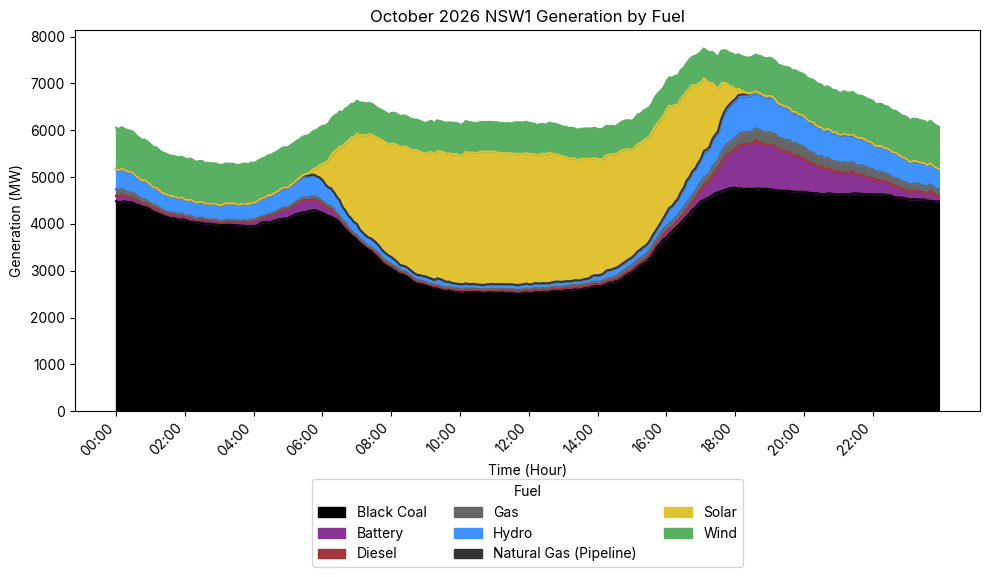

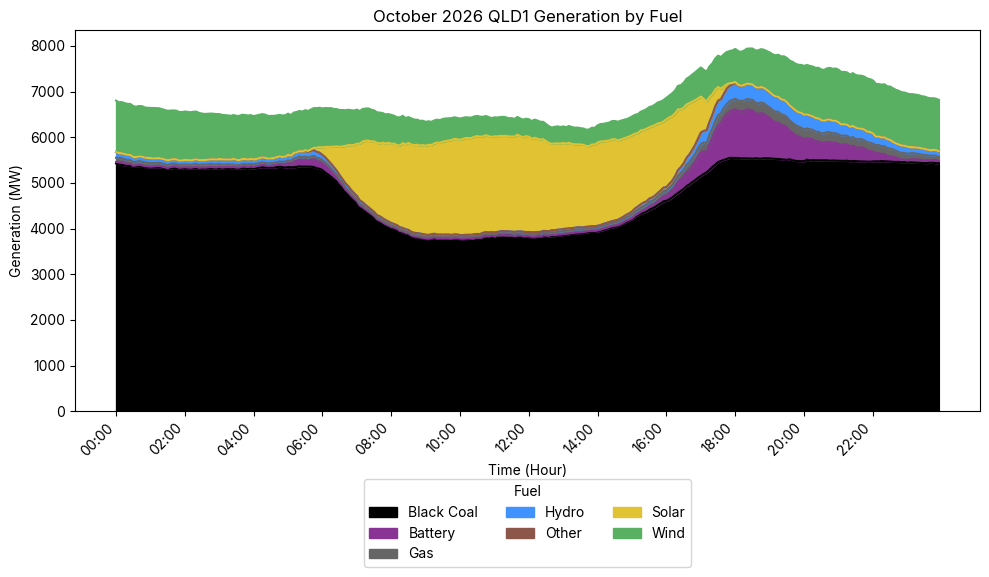

In [24]:
generation_colour_map = {
    'Black Coal': '#000000',
    'Brown Coal': '#73361C',
    'Gas': '#666666',
    'Diesel': '#A1343C',
    'Hydro': '#4092FF',
    'Wind': '#59B063',
    'Solar': '#E1C233',
    'Battery': '#893395',
    'Other': '#8c564b',
}

for region in target_regions:
    with plt.rc_context({
        'text.color': 'black',
        'axes.labelcolor': 'black',
        'axes.titlecolor': 'black',
        'axes.edgecolor': 'black',
        'axes.facecolor': 'white',
        'figure.facecolor': 'white',
        'savefig.facecolor': 'white',
        'grid.color': '#B0B0B0',
    }):
        generation_profiles[region]['current_month'].plot(
            kind='area',
            stacked=True,
            figsize=(10, 6),
            color=[
                generation_colour_map.get(fuel, '#333333')
                for fuel in generation_profiles[region]['current_month'].columns
            ],
        )
        plt.xlabel('Time (Hour)')
        plt.ylabel('Generation (MW)')
        plt.title(f'{month_name} {year} {region} Generation by Fuel')
        plt.xticks(
            range(0, 288, 24),
            [f'{hour:02d}:00' for hour in range(0, 24, 2)],
            rotation=45,
            ha='right',
        )
        plt.legend(
            title='Fuel',
            loc='upper center',
            bbox_to_anchor=(0.5, -0.16),
            ncol=3,
            frameon=True,
        )
        plt.tight_layout()
        plt.show()


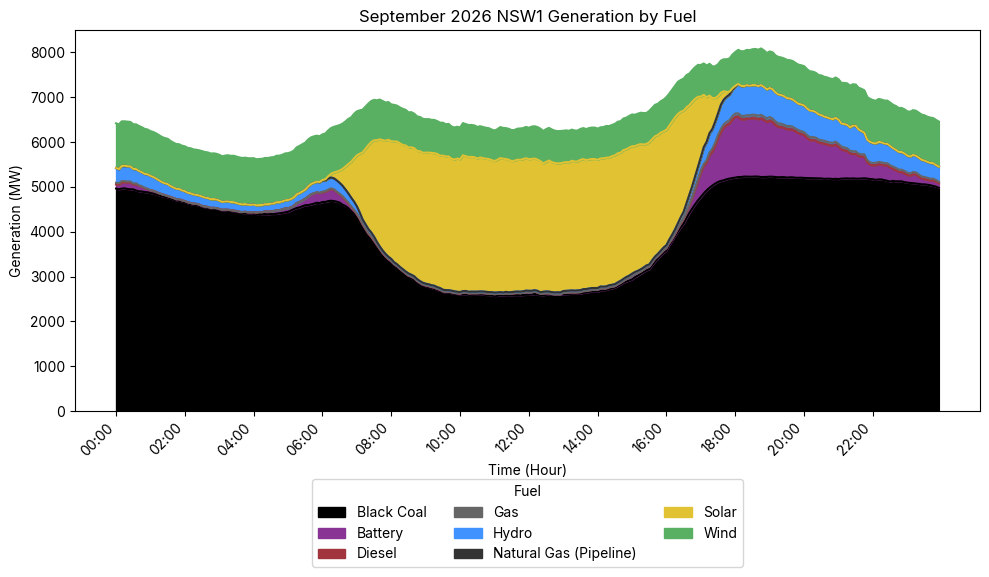

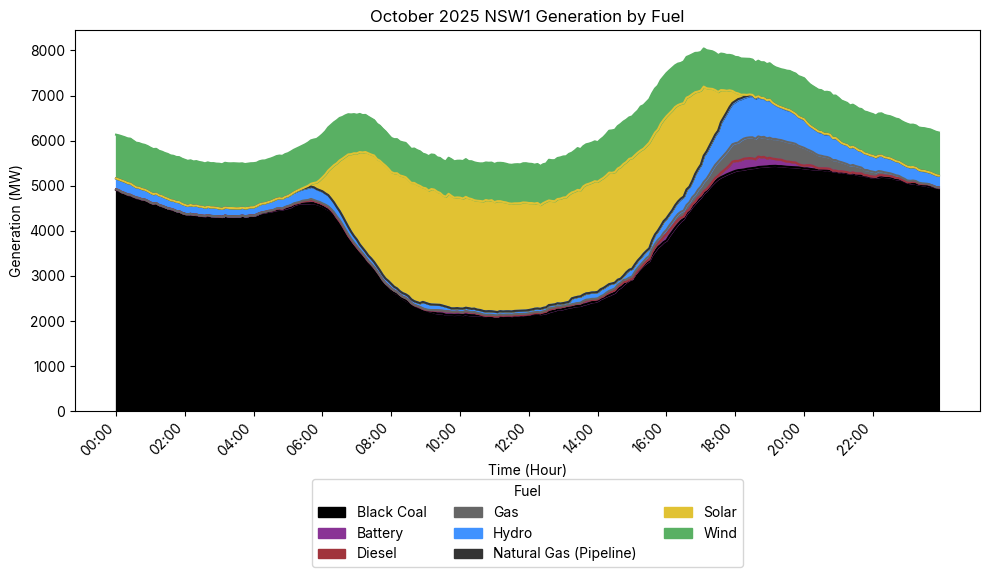

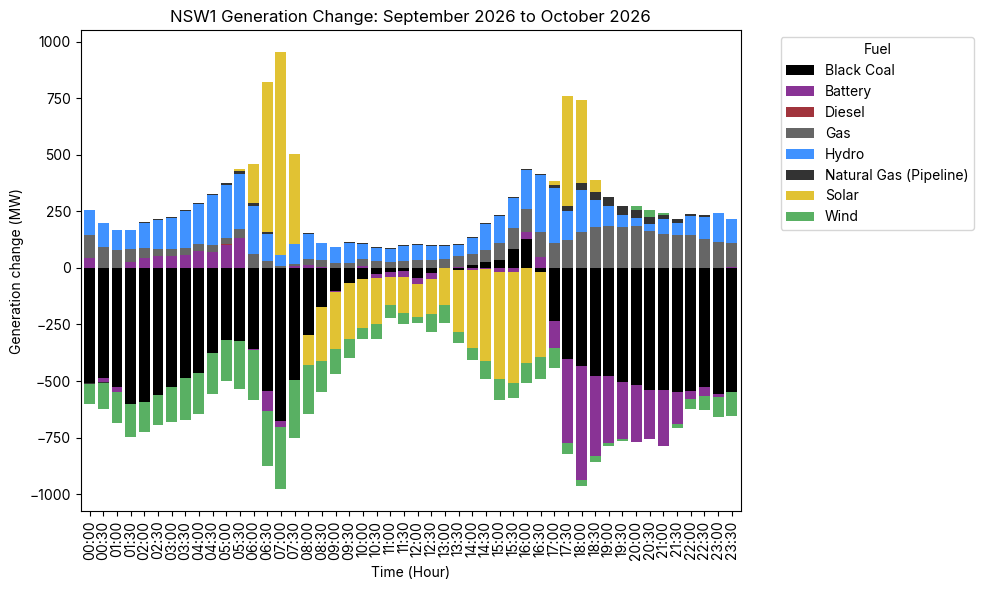

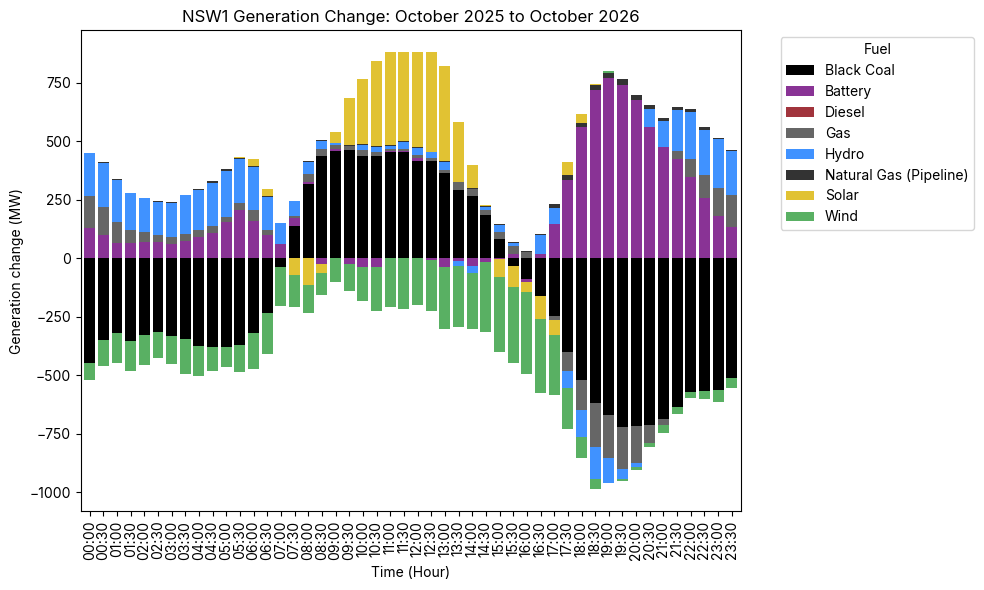

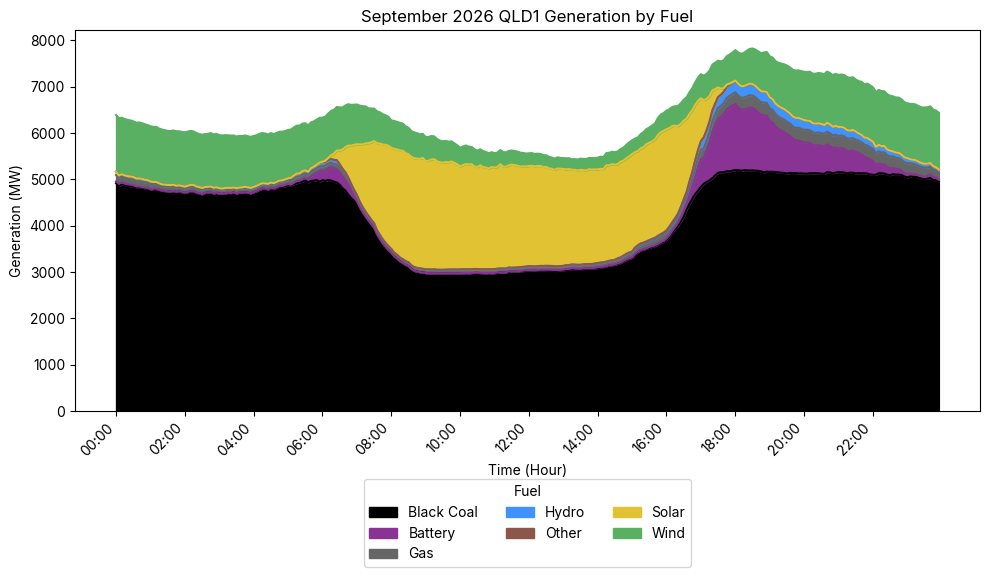

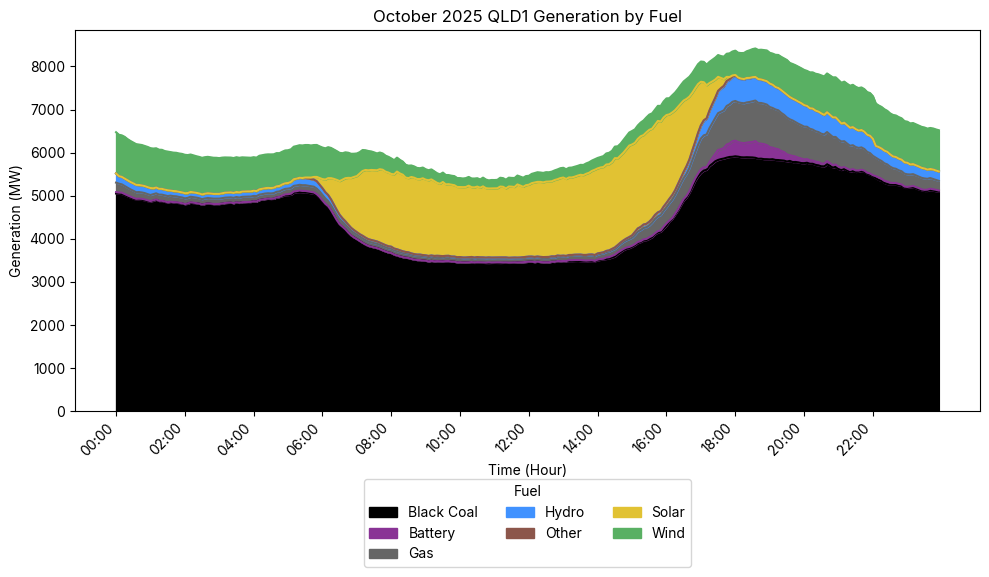

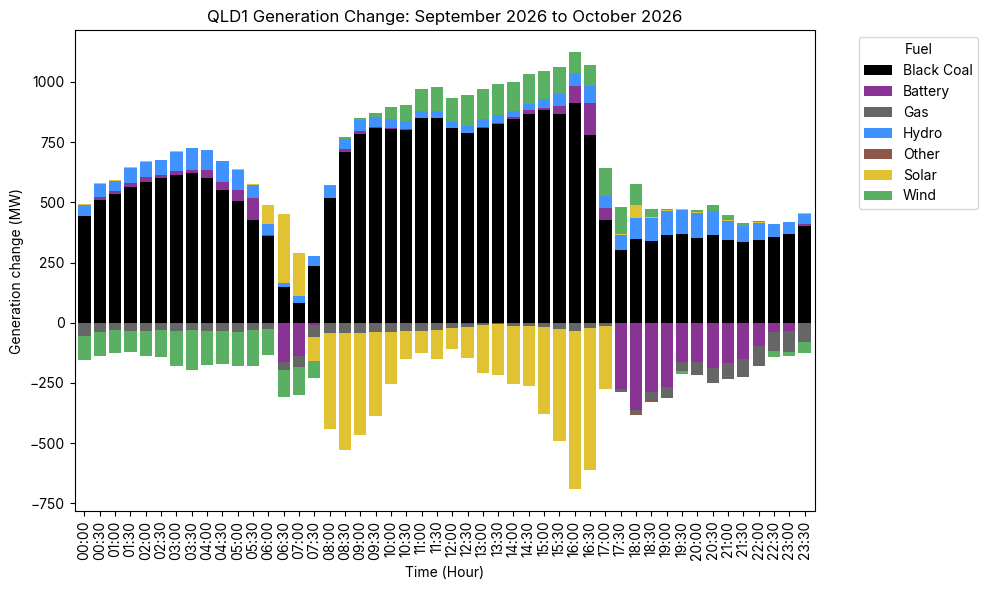

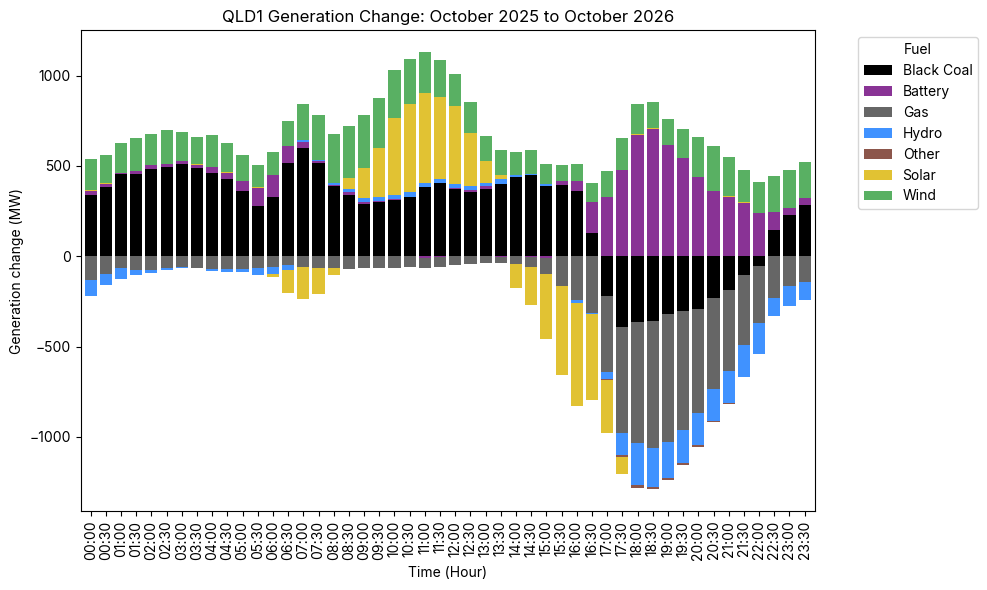

In [25]:
for region in target_regions:
    for profile_name, profile_title in [
        ('previous_month', f'{calendar.month_name[previous_month_start.month]} {year}'),
        ('previous_year', f'{month_name} {year - 1}'),
    ]:
        with plt.rc_context({
            'text.color': 'black',
            'axes.labelcolor': 'black',
            'axes.titlecolor': 'black',
            'axes.edgecolor': 'black',
            'axes.facecolor': 'white',
            'figure.facecolor': 'white',
            'savefig.facecolor': 'white',
            'grid.color': '#B0B0B0',
        }):
            generation_profiles[region][profile_name].plot(
                kind='area',
                stacked=True,
                figsize=(10, 6),
                color=[
                    generation_colour_map.get(fuel, '#333333')
                    for fuel in generation_profiles[region][profile_name].columns
                ],
            )
            plt.xlabel('Time (Hour)')
            plt.ylabel('Generation (MW)')
            plt.title(f'{profile_title} {region} Generation by Fuel')
            plt.xticks(
                range(0, 288, 24),
                [f'{hour:02d}:00' for hour in range(0, 24, 2)],
                rotation=45,
                ha='right',
            )
            plt.legend(
                title='Fuel',
                loc='upper center',
                bbox_to_anchor=(0.5, -0.16),
                ncol=3,
                frameon=True,
            )
            plt.tight_layout()
            plt.show()

    current_generation_by_half_hour = generation_half_hour[region]['current_month'].query(
        'Region == @region'
    )
    previous_generation_by_half_hour = generation_half_hour[region]['previous_month'].query(
        'Region == @region'
    )
    previous_year_generation_by_half_hour = generation_half_hour[region]['previous_year'].query(
        'Region == @region'
    )
    current_generation_profile = current_generation_by_half_hour.groupby(
        ['HH', 'Fuel'], as_index=False
    )['Generation'].mean().pivot(index='HH', columns='Fuel', values='Generation')
    previous_generation_profile = previous_generation_by_half_hour.groupby(
        ['HH', 'Fuel'], as_index=False
    )['Generation'].mean().pivot(index='HH', columns='Fuel', values='Generation')
    previous_year_generation_profile = previous_year_generation_by_half_hour.groupby(
        ['HH', 'Fuel'], as_index=False
    )['Generation'].mean().pivot(index='HH', columns='Fuel', values='Generation')

    generation_deltas = {
        'previous_month': current_generation_profile - previous_generation_profile,
        'previous_year': current_generation_profile - previous_year_generation_profile,
    }
    for comparison_name, delta in generation_deltas.items():
        ordered_columns = ['Black Coal'] + [
            column for column in delta.columns if column != 'Black Coal'
        ]
        delta = delta.reindex(columns=ordered_columns).copy()
        delta.index = half_hour_time_labels(delta.index).strftime('%H:%M')
        ax = delta.plot(
            kind='bar',
            stacked=True,
            figsize=(10, 6),
            width=0.8,
            color=[generation_colour_map.get(fuel, '#333333') for fuel in delta.columns],
        )
        comparison_label = (
            f'{calendar.month_name[previous_month_start.month]} {year}'
            if comparison_name == 'previous_month'
            else f'{month_name} {year - 1}'
        )
        plt.xlabel('Time (Hour)')
        plt.ylabel('Generation change (MW)')
        plt.title(f'{region} Generation Change: {comparison_label} to {month_name} {year}')
        plt.legend(title='Fuel', bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.tight_layout()
        plt.show()


## Availability by fuel type

This section retrieves unit availability (`MMS.DISPATCHLOAD.AVAILABILITY`, the availability used by the dispatch engine) summed by fuel for the reporting month, previous month, and previous year. It reports a fuel summary table, compares black coal availability across the three periods, shows daily availability by fuel, and provides a specific-day comparison against the month average (same inputs and layout approach as the specific day investigations). Availability is not imputed; review the quality reports first.

In [26]:
availability_data = {}
for region in target_regions:
    availability_data[region] = {
        'current_month': get_fueltype_availability(region, month_start, month_end),
        'previous_month': get_fueltype_availability(
            region, previous_month_start, previous_month_end
        ),
        'previous_year': get_fueltype_availability(
            region, previous_year_start, previous_year_end
        ),
    }

availability_quality_reports = {
    region: {
        comparison: build_time_series_quality_report(
            data, group_columns=['Fuel', 'Region']
        )
        for comparison, data in comparisons.items()
    }
    for region, comparisons in availability_data.items()
}
availability_quality_reports


c:\anaconda3\Lib\site-packages\urllib3\connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'www.neopoint.com.au'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
c:\anaconda3\Lib\site-packages\urllib3\connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'www.neopoint.com.au'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
c:\anaconda3\Lib\site-packages\urllib3\connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'www.neopoint.com.au'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
c:\anaconda3\Lib\site-packages\urllib3\connectionpool.py:1097: InsecureRequestWarn

{'NSW1': {'current_month': {'row_count': 71424,
   'duplicate_key_rows': 0,
   'incomplete_days': Empty DataFrame
   Columns: [Fuel, Region, _date, observed_intervals]
   Index: [],
   'gap_count': 0,
   'gaps': []},
  'previous_month': {'row_count': 69120,
   'duplicate_key_rows': 0,
   'incomplete_days': Empty DataFrame
   Columns: [Fuel, Region, _date, observed_intervals]
   Index: [],
   'gap_count': 0,
   'gaps': []},
  'previous_year': {'row_count': 71424,
   'duplicate_key_rows': 0,
   'incomplete_days': Empty DataFrame
   Columns: [Fuel, Region, _date, observed_intervals]
   Index: [],
   'gap_count': 0,
   'gaps': []}},
 'QLD1': {'current_month': {'row_count': 62496,
   'duplicate_key_rows': 0,
   'incomplete_days': Empty DataFrame
   Columns: [Fuel, Region, _date, observed_intervals]
   Index: [],
   'gap_count': 0,
   'gaps': []},
  'previous_month': {'row_count': 60480,
   'duplicate_key_rows': 0,
   'incomplete_days': Empty DataFrame
   Columns: [Fuel, Region, _date, obser

In [27]:
# Mean availability by fuel: reporting month vs previous month and previous year.
availability_summaries = {}
for region in target_regions:
    summary = summarise_availability(
        availability_data[region]['current_month'],
        availability_data[region]['previous_month'],
        availability_data[region]['previous_year'],
    )
    if 'Black Coal' in summary.index:
        summary = summary.loc[
            ['Black Coal'] + [fuel for fuel in summary.index if fuel != 'Black Coal']
        ]
    availability_summaries[region] = summary
    print(f'{region} availability by fuel ({month_name} {year})')
    display(summary.round(1))


NSW1 availability by fuel (October 2026)


,Current (MW),Previous month (MW),Previous year (MW),Change vs previous month (MW),Change vs previous month (%),Change vs previous year (MW),Change vs previous year (%),% of peak
Fuel,,,,,,,,
Black Coal,5270.8,5511.7,5473.8,-241.0,-4.4,-203.1,-3.7,81.2
Battery,1983.8,1623.8,409.1,360.0,22.2,1574.7,384.9,63.9
Diesel,19.4,19.5,19.8,-0.0,-0.2,-0.4,-1.9,97.1
Gas,1553.3,1394.6,1535.0,158.7,11.4,18.2,1.2,72.6
Hydro,2437.1,2287.5,2252.8,149.6,6.5,184.3,8.2,91.4
Natural Gas (Pipeline),11.3,1.9,3.4,9.5,505.5,7.9,229.6,3.1
Solar,1405.1,1449.2,1398.4,-44.1,-3.0,6.7,0.5,28.8
Wind,777.2,875.5,946.4,-98.3,-11.2,-169.2,-17.9,34.6


QLD1 availability by fuel (October 2026)


,Current (MW),Previous month (MW),Previous year (MW),Change vs previous month (MW),Change vs previous month (%),Change vs previous year (MW),Change vs previous year (%),% of peak
Fuel,,,,,,,,
Black Coal,5782.7,5455.6,6140.8,327.1,6.0,-358.1,-5.8,85.3
Battery,1951.6,1996.5,575.1,-45.0,-2.3,1376.5,239.3,69.9
Gas,830.8,1101.9,1256.1,-271.1,-24.6,-425.3,-33.9,31.6
Hydro,394.2,188.8,403.9,205.4,108.8,-9.7,-2.4,54.4
Other,362.9,361.6,370.3,1.4,0.4,-7.3,-2.0,91.7
Solar,974.5,1146.5,1070.9,-172.0,-15.0,-96.4,-9.0,25.5
Wind,819.7,864.3,621.8,-44.6,-5.2,197.9,31.8,41.6


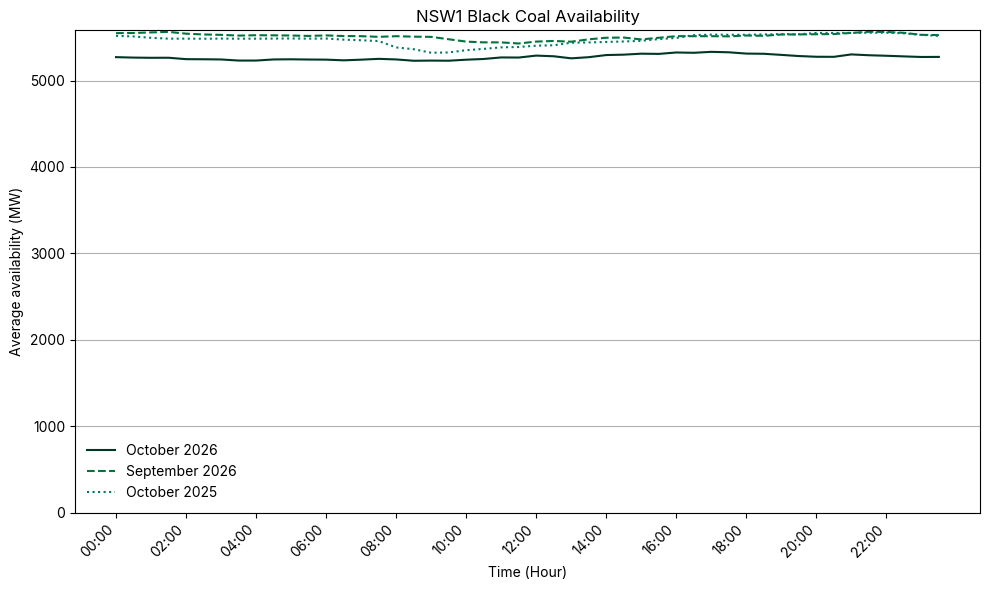

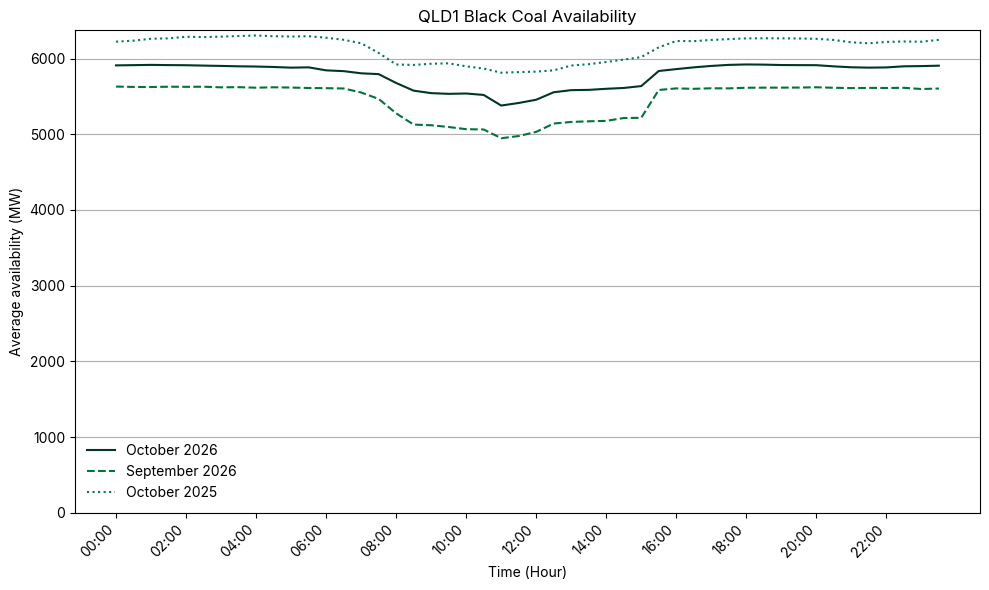

In [28]:
# Black coal half-hour availability profile: reporting month vs previous month vs previous year.
fuel_to_compare = 'Black Coal'

for region in target_regions:
    plt.figure(figsize=(10, 6))
    for comparison, label, line_style, color in [
        ('current_month', f'{month_name} {year}', '-', AKAYSHA_PINE),
        ('previous_month', f'{previous_month_name} {previous_month_start.year}', '--', AKAYSHA_MOSS),
        ('previous_year', f'{month_name} {year - 1}', ':', AKAYSHA_JADE),
    ]:
        profile = average_availability_profile(availability_data[region][comparison])
        if fuel_to_compare not in profile.columns:
            continue
        plt.plot(
            profile.index,
            profile[fuel_to_compare],
            label=label,
            linestyle=line_style,
            color=color,
        )
    plt.xlabel('Time (Hour)')
    plt.ylabel('Average availability (MW)')
    plt.title(f'{region} {fuel_to_compare} Availability')
    plt.xticks(
        range(1, 49, 4),
        [f'{hour:02d}:00' for hour in range(0, 24, 2)],
        rotation=45,
        ha='right',
    )
    plt.ylim(bottom=0)
    plt.grid(axis='y')
    plt.legend(frameon=False)
    plt.tight_layout()
    plt.show()


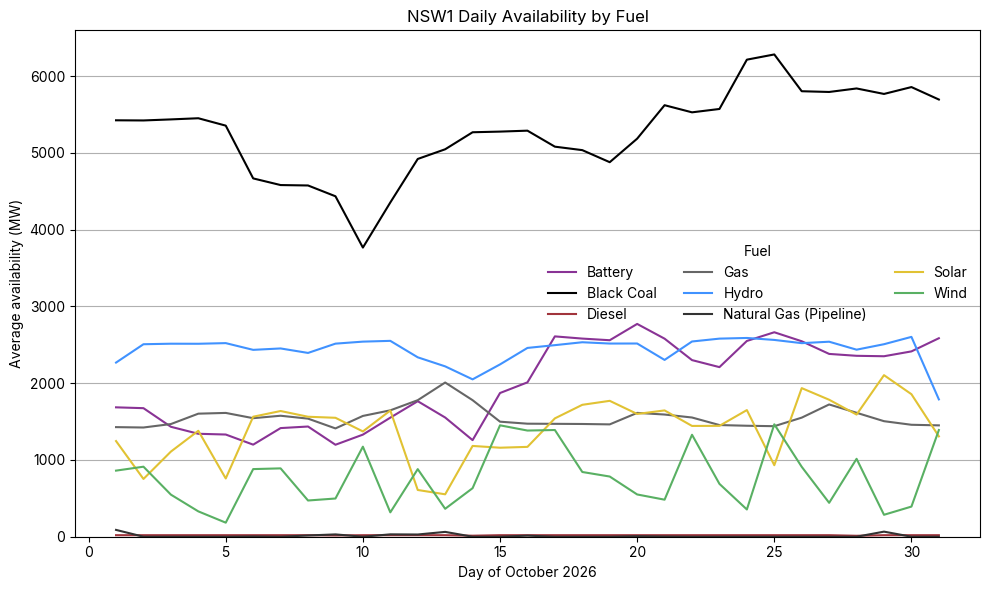

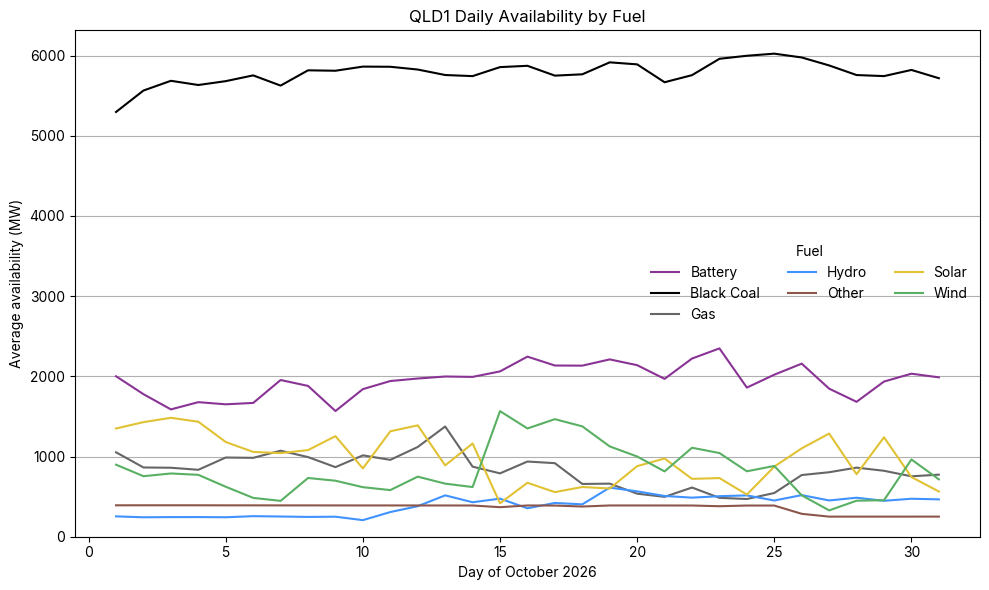

In [29]:
# Daily average availability by fuel for the reporting month.
for region in target_regions:
    daily_availability = daily_average_availability(
        availability_data[region]['current_month']
    )
    # The 00:00 interval of the 1st belongs to the previous settlement day; drop it.
    daily_availability = daily_availability[
        (daily_availability.index >= month_start)
        & (daily_availability.index < month_end)
    ]
    daily_availability.index = daily_availability.index.day
    ax = daily_availability.plot(
        figsize=(10, 6),
        color=[
            generation_colour_map.get(fuel, '#333333')
            for fuel in daily_availability.columns
        ],
    )
    ax.set_xlabel(f'Day of {month_name} {year}')
    ax.set_ylabel('Average availability (MW)')
    ax.set_title(f'{region} Daily Availability by Fuel')
    ax.set_ylim(bottom=0)
    ax.grid(axis='y')
    ax.legend(title='Fuel', ncol=3, frameon=False)
    plt.tight_layout()
    plt.show()


In [30]:
def plot_availability_investigation(
    investigation_start, investigation_end, investigation_region
):
    """Compare selected-day availability by fuel with the month average profile."""

    if investigation_start > investigation_end:
        raise ValueError(
            'investigation_start must be on or before investigation_end'
        )
    if investigation_region not in target_regions:
        raise ValueError(
            f'investigation_region must be one of the loaded target regions: '
            f'{target_regions}'
        )
    if (
        investigation_start.year != investigation_end.year
        or investigation_start.month != investigation_end.month
    ):
        raise ValueError(
            'The investigation period must fall within a single calendar month.'
        )

    selected_start = pd.Timestamp(investigation_start)
    # Exclusive upper bound. This includes every interval on investigation_end.
    selected_end = pd.Timestamp(investigation_end) + pd.Timedelta(days=1)
    comparison_month_start = selected_start.replace(day=1)
    comparison_month_end = comparison_month_start + pd.offsets.MonthBegin(1)

    all_availability = pd.concat(
        availability_data[investigation_region].values(), ignore_index=True
    ).drop_duplicates()
    all_availability['SETTLEMENTDATE'] = pd.to_datetime(
        all_availability['SETTLEMENTDATE']
    )

    selected_availability = all_availability[
        (all_availability['SETTLEMENTDATE'] >= selected_start)
        & (all_availability['SETTLEMENTDATE'] < selected_end)
    ]
    monthly_availability = all_availability[
        (all_availability['SETTLEMENTDATE'] >= comparison_month_start)
        & (all_availability['SETTLEMENTDATE'] < comparison_month_end)
    ]
    if selected_availability.empty or monthly_availability.empty:
        raise ValueError(
            'The selected date range has incomplete availability data for '
            f'{investigation_region}. Check that it is within the periods '
            'loaded above.'
        )

    selected_profile = average_availability_profile(selected_availability)
    monthly_profile = average_availability_profile(monthly_availability)
    all_fuels = sorted(set(selected_profile.columns) | set(monthly_profile.columns))
    selected_profile = selected_profile.reindex(columns=all_fuels).fillna(0)
    monthly_profile = monthly_profile.reindex(columns=all_fuels).fillna(0)

    # Positive values mean the selected days had more availability than the monthly average.
    difference_profile = selected_profile - monthly_profile

    selected_half_hour = (
        selected_availability
        .groupby(
            [
                pd.Grouper(
                    key='SETTLEMENTDATE', freq='30min', label='right', closed='right'
                ),
                'Fuel',
            ]
        )['Availability']
        .mean()
        .unstack('Fuel')
        .fillna(0)
        .sort_index()
    )

    figure, axes = plt.subplots(
        3, 1, figsize=(14, 12),
        gridspec_kw={'height_ratios': [1.1, 1.25, 1]},
    )

    def fuel_colours(columns):
        return [generation_colour_map.get(fuel, '#999999') for fuel in columns]

    difference_profile.plot(
        kind='bar', stacked=True, ax=axes[0], width=0.85,
        color=fuel_colours(difference_profile.columns),
    )
    axes[0].axhline(y=0, color='#333333', linewidth=0.8)
    axes[0].set_title('Average Availability Difference: Selected Days vs Monthly Average')
    axes[0].set_ylabel('Difference (MW)')
    axes[0].set_xlabel('Settlement period')
    axes[0].legend(loc='upper left', ncol=3, title=None)
    axes[0].set_xticks([0, 7, 15, 23, 31, 39, 47])
    axes[0].set_xticklabels(
        ['00:30', '04:00', '08:00', '12:00', '16:00', '20:00', '00:00'], rotation=0
    )

    selected_half_hour.plot.area(
        ax=axes[1], stacked=True, color=fuel_colours(selected_half_hour.columns), linewidth=0
    )
    axes[1].set_title(f'{investigation_region} Availability by Fuel')
    axes[1].set_ylabel('Availability (MW)')
    axes[1].set_xlabel('')
    axes[1].legend(loc='upper left', ncol=3, title=None)

    if 'Black Coal' in selected_half_hour.columns:
        shifted_index = selected_half_hour.index - pd.Timedelta(minutes=1)
        periods = shifted_index.hour * 2 + shifted_index.minute // 30 + 1
        coal_overlay = pd.Series(
            [monthly_profile['Black Coal'].get(period, np.nan) for period in periods],
            index=selected_half_hour.index,
        )
        selected_half_hour['Black Coal'].plot(
            ax=axes[2], color=AKAYSHA_PINE, linewidth=1.5, label='Selected period'
        )
        coal_overlay.plot(
            ax=axes[2], color=AKAYSHA_PINE, linewidth=1.5, linestyle=':',
            label=f'{comparison_month_start:%B %Y} average',
        )
        axes[2].set_ylim(bottom=0)
        axes[2].legend(loc='upper left')
    axes[2].set_title('Black Coal Availability')
    axes[2].set_ylabel('Availability (MW)')
    axes[2].set_xlabel('Settlement period')

    figure.suptitle(
        f'{investigation_region}: '
        f'{investigation_start:%d %b %Y} to {investigation_end:%d %b %Y}',
        y=0.995,
    )
    figure.tight_layout(rect=[0, 0, 1, 0.985])
    plt.show()


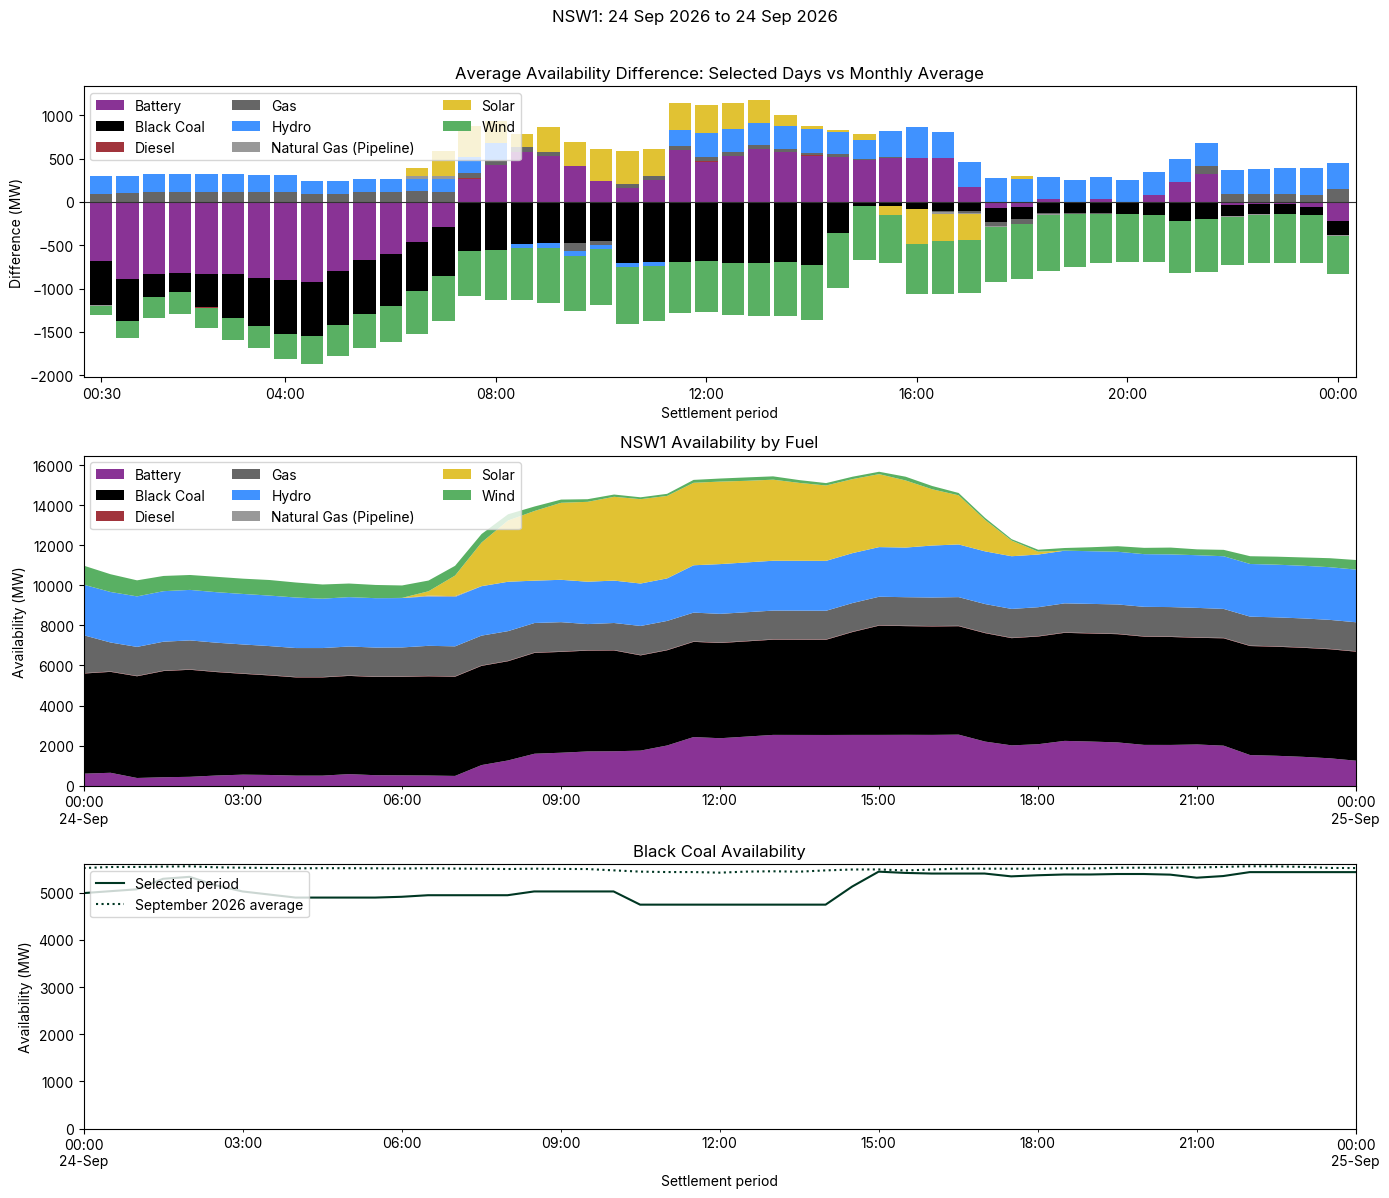

In [31]:
# Availability investigation inputs. The end date is inclusive.
availability_investigation_start = dt.date(2026, 9, 24)
availability_investigation_end = dt.date(2026, 9, 24)
availability_investigation_region = 'NSW1'

plot_availability_investigation(
    availability_investigation_start,
    availability_investigation_end,
    availability_investigation_region,
)


## Baseload and demand

This section calculates monthly baseload averages and half-hour operational-demand profiles for the reporting month, previous month, and previous year.

In [32]:
baseload = price_table[regions].copy()
baseload['Year'] = baseload.index.year
baseload['Month'] = baseload.index.month
baseload_monthly = baseload.groupby(['Year', 'Month'])[regions].mean()
baseload_monthly.tail()

REGIONID          NSW1       QLD1         SA1       TAS1       VIC1
Year Month                                                         
2026 9       65.319059  57.095786   37.696390  38.855904  36.818463
     10     127.829900  94.089836   49.702763  61.591153  52.942972
     11      85.610000  76.990000  120.430000  88.020000  86.790000

c:\anaconda3\Lib\site-packages\urllib3\connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'www.neopoint.com.au'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
c:\anaconda3\Lib\site-packages\urllib3\connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'www.neopoint.com.au'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
c:\anaconda3\Lib\site-packages\urllib3\connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'www.neopoint.com.au'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


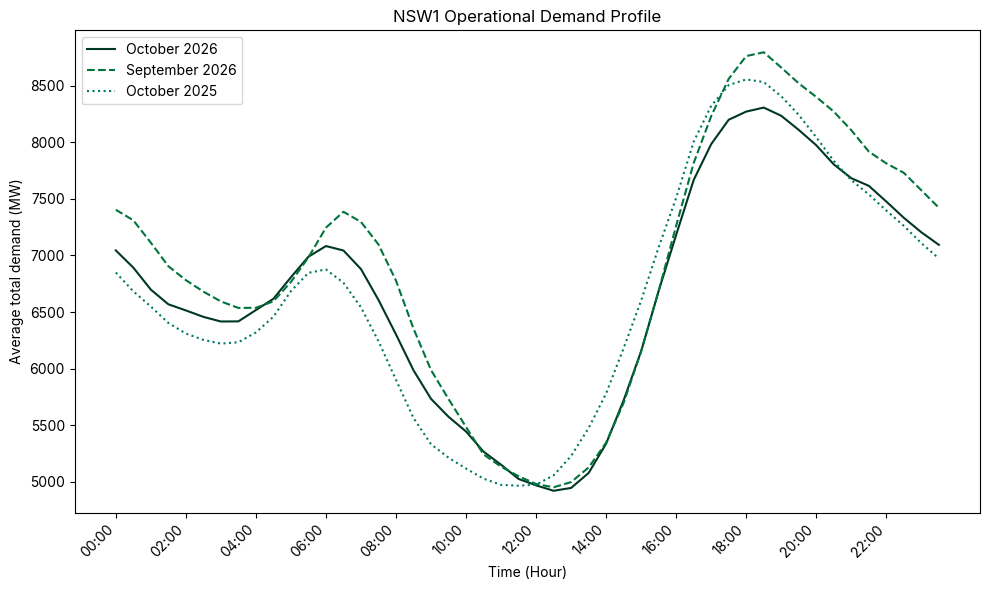

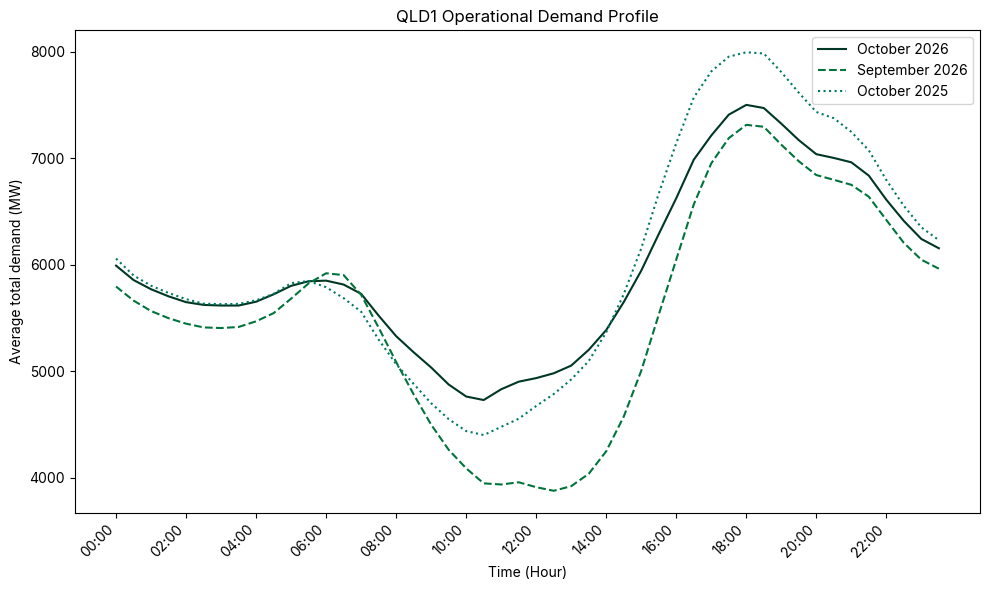

In [33]:
demand_current = get_operational_demand(month_start, month_end)
demand_previous = get_operational_demand(
    previous_month_start, previous_month_end
)
demand_previous_year = get_operational_demand(previous_year_start, previous_year_end)

demand_profiles = {
    'current_month': average_demand_by_half_hour(demand_current),
    'previous_month': average_demand_by_half_hour(demand_previous),
    'previous_year': average_demand_by_half_hour(demand_previous_year),
}

for region in target_regions:
    plt.figure(figsize=(10, 6))
    for profile_name, label, line_style, color in [
        ('current_month', f'{month_name} {year}', '-', AKAYSHA_PINE),
        ('previous_month', f'{previous_month_name} {year}', '--', AKAYSHA_MOSS),
        ('previous_year', f'{month_name} {year - 1}', ':', AKAYSHA_JADE),
    ]:
        region_demand = demand_profiles[profile_name]
        region_demand = region_demand[region_demand['REGIONID'] == region]
        plt.plot(
            region_demand['HH'],
            region_demand['TOTALDEMAND'],
            label=label,
            linestyle=line_style,
            color=color,
        )
    plt.xlabel('Time (Hour)')
    plt.ylabel('Average total demand (MW)')
    plt.title(f'{region} Operational Demand Profile')
    plt.xticks(
        range(0, 48, 4),
        [f'{hour:02d}:00' for hour in range(0, 24, 2)],
        rotation=45,
        ha='right',
    )
    plt.legend()
    plt.tight_layout()
    plt.show()


## Gas-weighted price

This section combines half-hour NSW1 generation and price data to calculate and plot the generation-weighted gas price for the reporting period.

NSW1 average gas-weighted price: 323.19 $/MWh


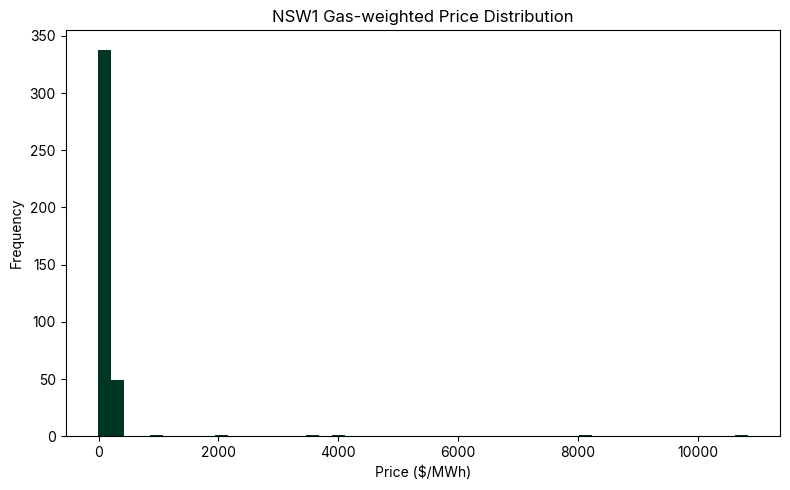

QLD1 average gas-weighted price: 144.67 $/MWh


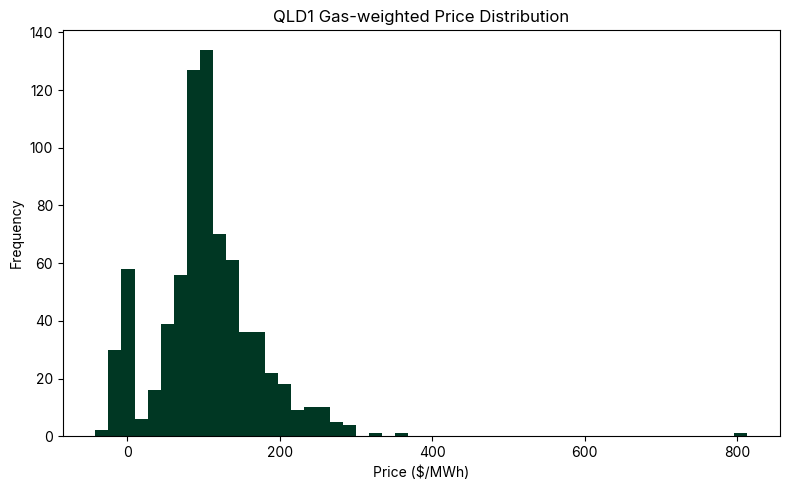

In [34]:
gas_weighted_prices = {}
for region in target_regions:
    gas_generation = generation_half_hour[region]['current_month'].query(
        "Fuel == 'Gas'"
    ).copy()
    price_half_hour = aggregate_to_half_hour(
        price_data[price_data['REGIONID'] == region],
        'Trading Price_5min',
        ['REGIONID'],
    )
    gas_price_data = price_half_hour.merge(
        gas_generation,
        on='SETTLEMENTDATE',
        how='left',
    )
    gas_price_data = gas_price_data[gas_price_data['Generation'] > 0].copy()
    gas_price_data = gas_price_data.rename(columns={'Trading Price_5min': 'Price'})
    gas_weighted_prices[region] = calculate_gas_weighted_price(gas_price_data)

    print(
        f'{region} average gas-weighted price: '
        f'{gas_weighted_prices[region]:.2f} $/MWh'
    )
    gas_price_data['Price'].plot(
        kind='hist',
        bins=50,
        figsize=(8, 5),
        title=f'{region} Gas-weighted Price Distribution',
        color=AKAYSHA_PINE,
    )
    plt.xlabel('Price ($/MWh)')
    plt.tight_layout()
    plt.show()


## Specific day investigations

Enter an inclusive date or date range and one of the configured target regions in the last cell of this section (run the helper cell above it first). The charts use the raw five-minute data loaded earlier in the notebook and aggregate it to half-hour settlement periods for readability. Dates must be within the price, generation, and demand periods loaded above.

In [35]:
def plot_investigation(investigation_start, investigation_end, investigation_region):
    """Plot the specific-day investigation. Inputs are set in the cell below."""

    # ------------------------------------------------------------------
    # Validation and date boundaries
    # ------------------------------------------------------------------

    if investigation_start > investigation_end:
        raise ValueError(
            'investigation_start must be on or before investigation_end'
        )

    if investigation_region not in target_regions:
        raise ValueError(
            f'investigation_region must be one of the loaded target regions: '
            f'{target_regions}'
        )

    if (
        investigation_start.year != investigation_end.year
        or investigation_start.month != investigation_end.month
    ):
        raise ValueError(
            'The investigation period must fall within a single calendar month.'
        )

    investigation_start_timestamp = pd.Timestamp(investigation_start)

    # Exclusive upper bound. This includes every interval on investigation_end.
    investigation_end_timestamp = (
        pd.Timestamp(investigation_end)
        + pd.Timedelta(days=1)
    )

    month_start_timestamp = investigation_start_timestamp.replace(day=1)
    month_end_timestamp = month_start_timestamp + pd.offsets.MonthBegin(1)


    # ------------------------------------------------------------------
    # Helper functions
    # ------------------------------------------------------------------

    def settlement_day(data, timestamp_column='SETTLEMENTDATE'):
        """
        Assign each timestamp to its NEM settlement day.

        The one-minute adjustment assigns midnight to the preceding
        settlement day.
        """
        timestamps = pd.to_datetime(data[timestamp_column])

        return (
            timestamps
            - pd.Timedelta(minutes=1)
        ).dt.normalize()


    def settlement_period(data, timestamp_column='SETTLEMENTDATE'):
        """
        Return the half-hour settlement period number from 1 to 48.

        The one-minute adjustment assigns 00:00 to period 48 of the
        preceding settlement day.
        """
        timestamps = (
            pd.to_datetime(data[timestamp_column])
            - pd.Timedelta(minutes=1)
        )

        return (
            timestamps.dt.hour * 2
            + timestamps.dt.minute // 30
            + 1
        )


    def half_hour_settlement_period(timestamp_index):
        """
        Map a right-labelled DatetimeIndex to settlement periods 1 to 48.
        """
        adjusted_index = timestamp_index - pd.Timedelta(minutes=1)

        return (
            adjusted_index.hour * 2
            + adjusted_index.minute // 30
            + 1
        )


    def create_profile_overlay(timestamp_index, profile):
        """
        Repeat a 48-period monthly-average profile across a DatetimeIndex.
        """
        periods = half_hour_settlement_period(timestamp_index)

        return pd.Series(
            [profile.get(period, np.nan) for period in periods],
            index=timestamp_index,
            name='Monthly average',
        )


    # ------------------------------------------------------------------
    # Combine the loaded source datasets
    # ------------------------------------------------------------------

    all_generation = pd.concat(
        [
            comparison_data
            for region_data in generation_data.values()
            for comparison_data in region_data.values()
        ],
        ignore_index=True,
    ).drop_duplicates()

    all_generation['SETTLEMENTDATE'] = pd.to_datetime(
        all_generation['SETTLEMENTDATE']
    )
    all_generation['SettlementDay'] = settlement_day(all_generation)
    all_generation['SettlementPeriod'] = settlement_period(all_generation)


    all_prices = price_data.copy()

    all_prices['SETTLEMENTDATE'] = pd.to_datetime(
        all_prices['SETTLEMENTDATE']
    )
    all_prices['SettlementDay'] = settlement_day(all_prices)
    all_prices['SettlementPeriod'] = settlement_period(all_prices)


    all_demand = pd.concat(
        [
            demand_current,
            demand_previous,
            demand_previous_year,
        ],
        ignore_index=True,
    ).drop_duplicates()

    all_demand['SETTLEMENTDATE'] = pd.to_datetime(
        all_demand['SETTLEMENTDATE']
    )
    all_demand['SettlementDay'] = settlement_day(all_demand)
    all_demand['SettlementPeriod'] = settlement_period(all_demand)


    # ------------------------------------------------------------------
    # Filter the selected investigation period
    # ------------------------------------------------------------------

    loaded_generation = all_generation[
        (all_generation['Region'] == investigation_region)
        & (
            all_generation['SETTLEMENTDATE']
            >= investigation_start_timestamp
        )
        & (
            all_generation['SETTLEMENTDATE']
            < investigation_end_timestamp
        )
    ].copy()


    investigation_prices = all_prices[
        (all_prices['REGIONID'] == investigation_region)
        & (
            all_prices['SETTLEMENTDATE']
            >= investigation_start_timestamp
        )
        & (
            all_prices['SETTLEMENTDATE']
            < investigation_end_timestamp
        )
    ].copy()


    investigation_demand = all_demand[
        (all_demand['REGIONID'] == investigation_region)
        & (
            all_demand['SETTLEMENTDATE']
            >= investigation_start_timestamp
        )
        & (
            all_demand['SETTLEMENTDATE']
            < investigation_end_timestamp
        )
    ].copy()


    # ------------------------------------------------------------------
    # Filter the full calendar month for comparison profiles
    # ------------------------------------------------------------------

    monthly_generation = all_generation[
        (all_generation['Region'] == investigation_region)
        & (
            all_generation['SETTLEMENTDATE']
            >= month_start_timestamp
        )
        & (
            all_generation['SETTLEMENTDATE']
            < month_end_timestamp
        )
    ].copy()


    monthly_prices = all_prices[
        (all_prices['REGIONID'] == investigation_region)
        & (
            all_prices['SETTLEMENTDATE']
            >= month_start_timestamp
        )
        & (
            all_prices['SETTLEMENTDATE']
            < month_end_timestamp
        )
    ].copy()


    monthly_demand = all_demand[
        (all_demand['REGIONID'] == investigation_region)
        & (
            all_demand['SETTLEMENTDATE']
            >= month_start_timestamp
        )
        & (
            all_demand['SETTLEMENTDATE']
            < month_end_timestamp
        )
    ].copy()


    # ------------------------------------------------------------------
    # Check that the required data is available
    # ------------------------------------------------------------------

    if (
        loaded_generation.empty
        or investigation_prices.empty
        or investigation_demand.empty
    ):
        raise ValueError(
            'The selected date range has incomplete data for '
            f'{investigation_region}. Check that it is within the '
            'periods loaded above.'
        )

    if (
        monthly_generation.empty
        or monthly_prices.empty
        or monthly_demand.empty
    ):
        raise ValueError(
            'Monthly comparison data is incomplete for '
            f'{investigation_region} in '
            f'{month_start_timestamp:%B %Y}.'
        )


    # ------------------------------------------------------------------
    # Resample selected-period data to half-hour resolution
    # ------------------------------------------------------------------

    generation_half_hour = (
        loaded_generation
        .groupby(
            [
                pd.Grouper(
                    key='SETTLEMENTDATE',
                    freq='30min',
                    label='right',
                    closed='right',
                ),
                'Fuel',
            ],
            as_index=False,
        )['Generation']
        .mean()
        .pivot(
            index='SETTLEMENTDATE',
            columns='Fuel',
            values='Generation',
        )
        .fillna(0)
        .sort_index()
    )


    price_half_hour = (
        investigation_prices
        .set_index('SETTLEMENTDATE')['Trading Price_5min']
        .resample(
            '30min',
            label='right',
            closed='right',
        )
        .mean()
        .sort_index()
    )


    demand_half_hour = (
        investigation_demand
        .set_index('SETTLEMENTDATE')['TOTALDEMAND']
        .resample(
            '30min',
            label='right',
            closed='right',
        )
        .mean()
        .sort_index()
    )


    # ------------------------------------------------------------------
    # Selected-days average generation profile
    # ------------------------------------------------------------------

    selected_generation_profile_data = generation_half_hour.copy()

    selected_generation_profile_data['SettlementPeriod'] = (
        half_hour_settlement_period(
            selected_generation_profile_data.index
        )
    )

    selected_generation_profile = (
        selected_generation_profile_data
        .groupby('SettlementPeriod')
        .mean()
        .reindex(range(1, 49))
        .fillna(0)
    )


    # ------------------------------------------------------------------
    # Monthly-average generation profile
    # ------------------------------------------------------------------

    # First calculate fuel generation for each underlying timestamp.
    monthly_generation_interval = (
        monthly_generation
        .groupby(
            [
                'SETTLEMENTDATE',
                'SettlementDay',
                'SettlementPeriod',
                'Fuel',
            ],
            as_index=False,
        )['Generation']
        .mean()
    )

    # Then average across all days in the month by settlement period.
    monthly_generation_profile = (
        monthly_generation_interval
        .groupby(
            [
                'SettlementPeriod',
                'Fuel',
            ],
            as_index=False,
        )['Generation']
        .mean()
        .pivot(
            index='SettlementPeriod',
            columns='Fuel',
            values='Generation',
        )
        .reindex(range(1, 49))
        .fillna(0)
    )


    # Ensure both generation profiles use the same fuel columns.
    all_fuels = sorted(
        set(selected_generation_profile.columns)
        | set(monthly_generation_profile.columns)
    )

    selected_generation_profile = (
        selected_generation_profile
        .reindex(
            index=range(1, 49),
            columns=all_fuels,
            fill_value=0,
        )
    )

    monthly_generation_profile = (
        monthly_generation_profile
        .reindex(
            index=range(1, 49),
            columns=all_fuels,
            fill_value=0,
        )
    )


    # Positive values mean the selected days had more generation than
    # the monthly average. Negative values mean they had less.
    generation_difference_profile = (
        selected_generation_profile
        - monthly_generation_profile
    )


    # ------------------------------------------------------------------
    # Monthly-average price profile
    # ------------------------------------------------------------------

    # Calculate a half-hour price for every settlement day and period.
    monthly_price_by_day = (
        monthly_prices
        .groupby(
            [
                'SettlementDay',
                'SettlementPeriod',
            ],
            as_index=False,
        )['Trading Price_5min']
        .mean()
    )

    # Average the corresponding settlement periods across the month.
    monthly_price_profile = (
        monthly_price_by_day
        .groupby('SettlementPeriod')['Trading Price_5min']
        .mean()
        .reindex(range(1, 49))
    )


    # ------------------------------------------------------------------
    # Monthly-average operational-demand profile
    # ------------------------------------------------------------------

    monthly_demand_by_day = (
        monthly_demand
        .groupby(
            [
                'SettlementDay',
                'SettlementPeriod',
            ],
            as_index=False,
        )['TOTALDEMAND']
        .mean()
    )

    monthly_demand_profile = (
        monthly_demand_by_day
        .groupby('SettlementPeriod')['TOTALDEMAND']
        .mean()
        .reindex(range(1, 49))
    )


    # ------------------------------------------------------------------
    # Repeat monthly profiles across the selected period
    # ------------------------------------------------------------------

    price_monthly_overlay = create_profile_overlay(
        price_half_hour.index,
        monthly_price_profile,
    )

    demand_monthly_overlay = create_profile_overlay(
        demand_half_hour.index,
        monthly_demand_profile,
    )


    # ------------------------------------------------------------------
    # Plot
    # ------------------------------------------------------------------

    figure, axes = plt.subplots(
        4,
        1,
        figsize=(14, 15),
        sharex=False,
        gridspec_kw={
            'height_ratios': [1.1, 1.25, 1, 1],
        },
    )


    # Generation difference from monthly average
    generation_difference_profile.plot(
        kind='bar',
        stacked=True,
        ax=axes[0],
        width=0.85,
        color=[
            generation_colour_map.get(fuel, '#999999')
            for fuel in generation_difference_profile.columns
        ],
    )

    axes[0].axhline(
        y=0,
        color='#333333',
        linewidth=0.8,
    )

    axes[0].set_title(
        'Average Generation Difference: '
        'Selected Days vs Monthly Average'
    )
    axes[0].set_ylabel('Difference (MW)')
    axes[0].set_xlabel('Settlement period')
    axes[0].legend(
        loc='upper left',
        ncol=3,
        title=None,
    )

    axes[0].set_xticks(
        [0, 7, 15, 23, 31, 39, 47]
    )
    axes[0].set_xticklabels(
        [
            '00:30',
            '04:00',
            '08:00',
            '12:00',
            '16:00',
            '20:00',
            '00:00',
        ],
        rotation=0,
    )


    # Selected-period generation mix
    generation_half_hour.plot.area(
        ax=axes[1],
        stacked=True,
        color=[
            generation_colour_map.get(fuel, '#999999')
            for fuel in generation_half_hour.columns
        ],
        linewidth=0,
    )

    axes[1].set_title(
        f'{investigation_region} Generation Mix'
    )
    axes[1].set_ylabel('Generation (MW)')
    axes[1].set_xlabel('')
    axes[1].legend(
        loc='upper left',
        ncol=3,
        title=None,
    )


    # Price and monthly-average price profile
    price_half_hour.plot(
        ax=axes[2],
        color=AKAYSHA_AMARANTH,
        linewidth=1.5,
        label='Selected period',
    )

    price_monthly_overlay.plot(
        ax=axes[2],
        color=AKAYSHA_AMARANTH,
        linewidth=1.5,
        linestyle=':',
        label=f'{month_start_timestamp:%B %Y} average',
    )

    axes[2].set_title('Price')
    axes[2].set_ylabel('Price ($/MWh)')
    axes[2].set_xlabel('')
    axes[2].legend(loc='upper left')


    # Demand and monthly-average operational-demand profile
    demand_half_hour.plot(
        ax=axes[3],
        color=AKAYSHA_AZURE,
        linewidth=1.5,
        label='Selected period',
    )

    demand_monthly_overlay.plot(
        ax=axes[3],
        color=AKAYSHA_AZURE,
        linewidth=1.5,
        linestyle=':',
        label=f'{month_start_timestamp:%B %Y} average',
    )

    axes[3].set_title('Operational Demand')
    axes[3].set_ylabel('Demand (MW)')
    axes[3].set_xlabel('Settlement period')
    axes[3].legend(loc='upper left')


    figure.suptitle(
        f'{investigation_region}: '
        f'{investigation_start:%d %b %Y} to '
        f'{investigation_end:%d %b %Y}',
        y=0.995,
    )

    figure.tight_layout(
        rect=[0, 0, 1, 0.985]
    )

    plt.show()

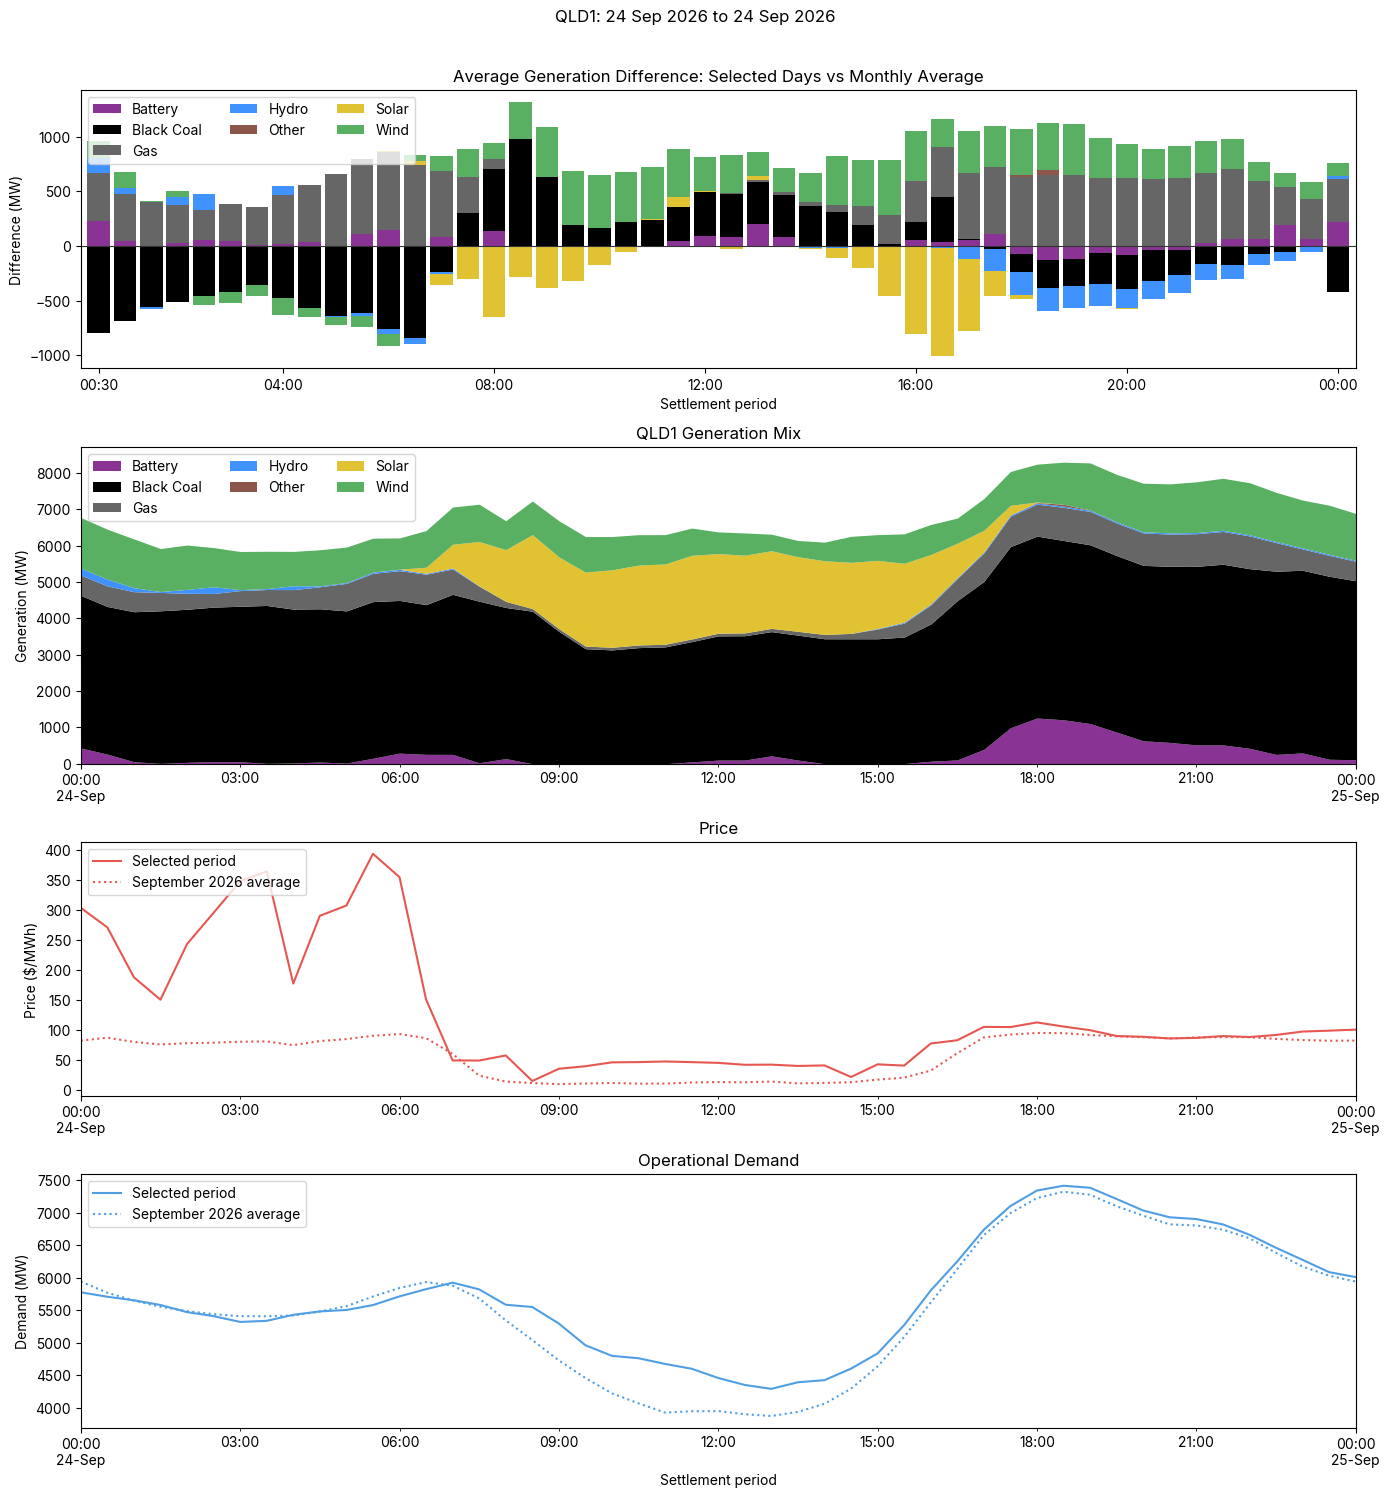

In [36]:
# Investigation inputs. The end date is inclusive.
investigation_start = dt.date(2026, 9, 24)
investigation_end = dt.date(2026, 9, 24)
investigation_region = 'QLD1'

plot_investigation(investigation_start, investigation_end, investigation_region)